# Física Computacional
**Sergio A. Alcalá Corona, Rodrigo Vega Vilchis y Joel Gómez Uribe**  
**Grupo 8270**  
**Semestre 2027-1**  

## Tarea-Práctica 4. Métodos de Integración numérica
**Fecha de entrega:** 21 de octubre de 2026

**Alumno: Diego Alessandro Santiago Martínez**
**Número de cuenta: 424138684**

### 1. Regla del Trapecio

El archivo `velocidades.txt` (adjunto), contiene dos columnas de números, la primera representa el tiempo $t$ en segundos y la segunda la x-velocidad en metros por segundo de una partícula, medida una vez por segundo desde el tiempo $t=0$ hasta $t=100$. Las primeras líneas se ven así:

```text
0 0
1 0.069478
2 0.137694
3 0.204332
4 0.269083
5 0.331656
```

Escribe un programa para hacer lo siguiente:

**(a)** Lee los datos y, usando la regla del trapecio, calcula a partir de ellos la distancia aproximada recorrida por la partícula en la dirección x como una función del tiempo.

**(b)** Extiende tu programa para hacer una gráfica que muestre, en el mismo gráfico, tanto la curva de velocidad original como la distancia recorrida como una función del tiempo.

---

**Inciso a)**

In [1]:
t,v = [],[]
with open("data/velocidades.txt", "r") as archivo:
    for linea in archivo:
        separacion = linea.split()
        t.append(int(separacion[0]))
        v.append(float(separacion[1]))

In [2]:
def velocidad(t):
    if t < 0 or t > 100:
        raise ValueError("Solo está definida para los primeros 100 segundos.")
    else:
        return v[int(t)]

def Trapecio(f,a,b,N):
    h = (b-a)/N

    Integral = 0
    Int1 = (f(a)+f(b))/2

    for i in range(1, N):
        Integral += f(a+i*h)

    I = h*(Integral + Int1)
    return I

x = [0.0]
for j in range(1,len(t)):
    x_j  = Trapecio(velocidad,0,j,j)
    x.append(round(x_j,3))
print("La siguiente tabla muestra la posición de la partícula como función del tiempo.")
print("Tiempo [s] --- Posición [m]")
for i in range(len(t)):
    print(t[i], "     ---     ", x[i])


La siguiente tabla muestra la posición de la partícula como función del tiempo.
Tiempo [s] --- Posición [m]
0      ---      0.0
1      ---      0.035
2      ---      0.138
3      ---      0.309
4      ---      0.546
5      ---      0.846
6      ---      1.208
7      ---      1.629
8      ---      2.105
9      ---      2.634
10      ---      3.213
11      ---      3.838
12      ---      4.505
13      ---      5.211
14      ---      5.951
15      ---      6.721
16      ---      7.518
17      ---      8.337
18      ---      9.174
19      ---      10.024
20      ---      10.883
21      ---      11.747
22      ---      12.611
23      ---      13.471
24      ---      14.323
25      ---      15.163
26      ---      15.987
27      ---      16.791
28      ---      17.571
29      ---      18.325
30      ---      19.047
31      ---      19.737
32      ---      20.389
33      ---      21.003
34      ---      21.574
35      ---      22.102
36      ---      22.583
37      ---      23.017
38      ---

**Inciso b)**

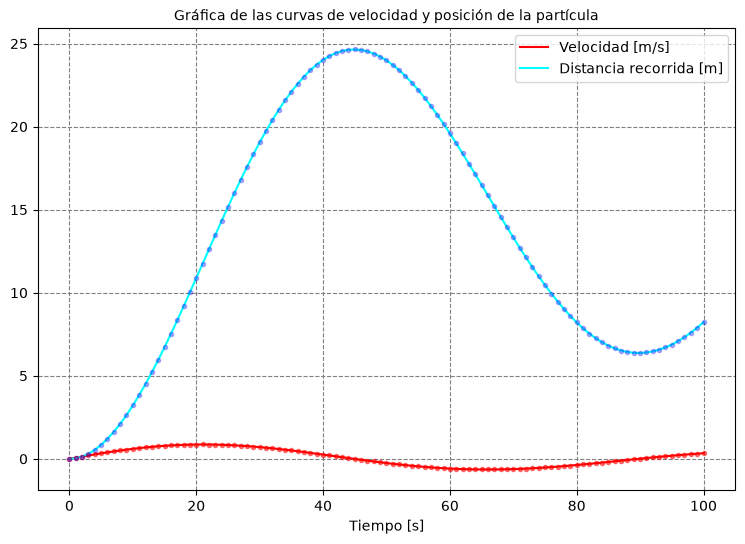

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,6))
plt.title("Gráfica de las curvas de velocidad y posición de la partícula", fontsize = 10)

plt.plot(t, v, color = "red", label="Velocidad [m/s]")
plt.plot(t, x, color = "cyan", label="Distancia recorrida [m]")
plt.plot(t,v, "r.", alpha = 0.5)
plt.plot(t,x, "b.", alpha = 0.3)
plt.xlabel("Tiempo [s]")
plt.legend()
plt.grid(linestyle = "--", color = "gray")
plt.show()

### 2. El límite de difracción de un telescopio

Nuestra capacidad para resolver detalles en observaciones astronómicas está limitada por la difracción de la luz en nuestros telescopios. La luz de las estrellas puede considerarse efectivamente como si proviniera de una fuente puntual en el infinito. Cuando dicha luz, con una longitud de onda $\lambda$, pasa a través de la apertura circular de un telescopio (que supondremos que tiene un radio unitario) y es enfocada por el telescopio en el plano focal, no produce un solo punto, sino un patrón de difracción circular que consta de un punto central rodeado por una serie de anillos concéntricos. 

La intensidad de la luz en este patrón de difracción está dada por:

$$ I(r) = \left(\frac{J_1(kr)}{kr}\right)^2 $$

donde $r$ es la distancia en el plano focal desde el centro del patrón de difracción, $k = \frac{2\pi}{\lambda}$ y $J_1(x)$ es una función de Bessel. Las funciones de Bessel $J_m(x)$ están dadas por:

$$ J_m(x) = \frac{1}{\pi} \int_0^\pi \cos(m	\theta - x \sin	\theta) d	\theta $$

donde $m$ es un entero no negativo y $x \ge 0$.

**(a)** Escribe una función $J(m,x)$ que calcule el valor de $J_m(x)$ usando la regla de Simpson con $N=1000$ puntos. Utiliza dicha función en un programa para graficar, en un solo gráfico, las funciones de Bessel $J_0$, $J_1$ y $J_2$ como una función de $x$ (de $x=0$ a $x=20$).

**(b)** Compara tus resultados con los proporcionados con la biblioteca de scipy que implementa la regla de Simpson.

**(c)** Escribe un segundo programa que haga una gráfica de densidad (*density plot*) de la intensidad del patrón de difracción circular de una fuente de luz puntual con $\lambda=500	\text{ nm}$, en una región cuadrada del plano focal, usando la fórmula dada anteriormente. Su imagen debe cubrir valores de $r$ desde cero hasta aproximadamente $1\mu	\text{m}$.

* **Hint 1:** Puede resultarte útil saber que
$$ \lim_{x \rightarrow 0} \frac{J_1(x)}{x} =\frac{1}{2} $$

* **Hint 2:** El punto central en el patrón de difracción es tan brillante que puede resultar difícil ver los anillos que lo rodean en la pantalla de la computadora; para solucionar esta situación puedes usar el esquema "hot" funciona bien.

**Inciso a)**

In [1]:
import numpy as np

def simpson1(f,a,b,n):
    if n%2 != 0 or n < 0:
        raise ValueError("Este método requiere de una cantidad positiva par de puntos en la refinación del intervalo.")
    h = (b-a)/n
    suma1 = 0
    suma2 = 0
    N = int(n/2)
    for k in range(1,N+1):
        suma1 += f(a+(2*k-1)*h)
    for j in range(1,N):
        suma2 += f(a+(2*j*h))
    IntegralAprox = (1/3)*h*((f(a) + f(b)) + 4*suma1 + 2*suma2)
    return IntegralAprox
    


def BesselJ(m,x):
    if m < 0:
        raise ValueError("Las funciones de Bessel de orden m de primer tipo solo admiten enteros no negativos.")
    elif isinstance(m,float):
        raise TypeError("No hay ordenes decimales para las funciones de Bessel de primer tipo.")
    elif x < 0:
        raise ValueError("Solo están definidos para argumentos no negativos.")
    def integrando(θ):
        return np.cos(m*θ - x*np.sin(θ))
    return (1/np.pi)*simpson1(integrando,0,np.pi,1000)
    

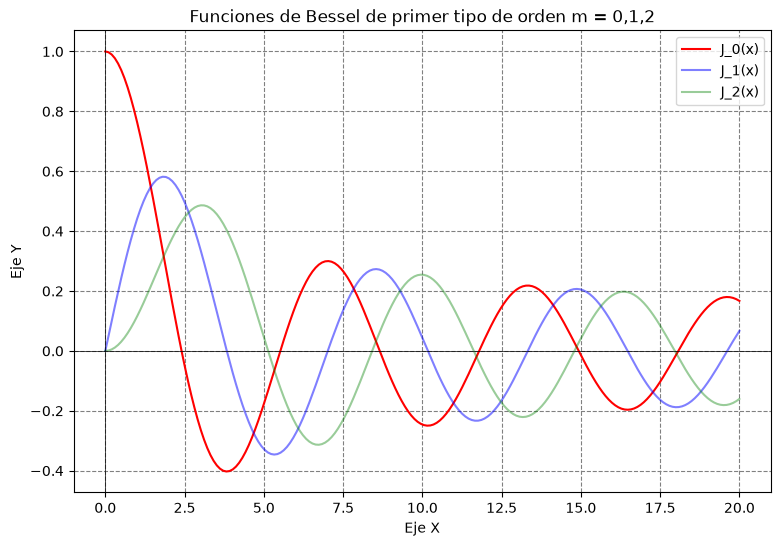

In [2]:
import matplotlib.pyplot as plt

ejehorizontal = np.linspace(0,20,200)
ejesverticales = [[],[],[],]
for m in range(0,3):
    for i in range (0,len(ejehorizontal)):
        x_i = ejehorizontal[i]
        y_i = BesselJ(m,x_i)
        ejesverticales[m].append(y_i)

plt.figure(figsize=(9,6))

plt.title("Funciones de Bessel de primer tipo de orden m = 0,1,2")
plt.plot(ejehorizontal,ejesverticales[0], color = "red", label = "J_0(x)")
plt.plot(ejehorizontal,ejesverticales[1], color = "blue", alpha = 0.5, label = "J_1(x)")
plt.plot(ejehorizontal,ejesverticales[2], color = "green", alpha=0.4, label = "J_2(x)")
plt.legend()
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.axhline(y = 0, xmin = 0, color = 'black', linewidth = 0.5)
plt.axvline(x = 0, ymin = 0.0, color = 'black', linewidth = 0.5)
plt.grid(linestyle = "--", color = "gray")

**Inciso b)**

In [3]:
import numpy as np
import scipy as sp

def J(m, x):
    theta = np.linspace(0, np.pi, 1000)
    y = np.cos(m * theta - x * np.sin(theta))
    return (1 / np.pi) * sp.integrate.simpson(y, theta)

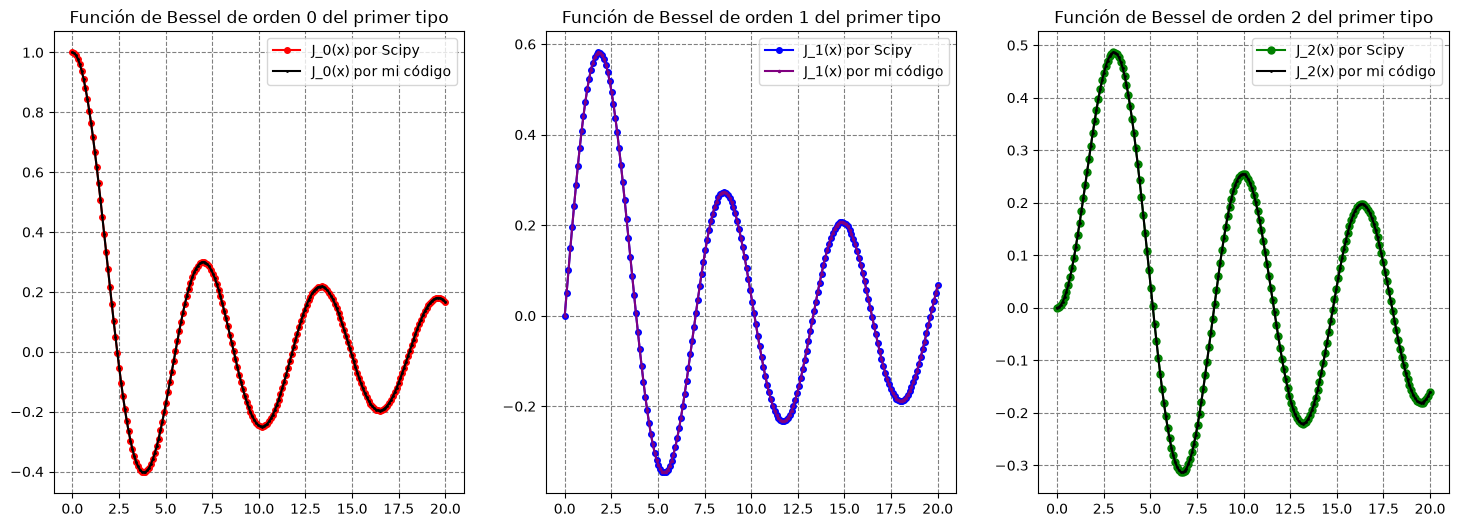

In [4]:
import matplotlib.pyplot as plt

y_scipy = [[],[],[]]

for m in range(0,3):
    for k in range(0,len(ejehorizontal)):
        resultado_i = J(m,ejehorizontal[k])
        y_scipy[m].append(resultado_i)

plt.figure(figsize=(18,6))

plt.subplot(131)
plt.title("Función de Bessel de orden 0 del primer tipo")
plt.plot(ejehorizontal,y_scipy[0], ".-", markersize = 8, color = "red", label = "J_0(x) por Scipy")
plt.plot(ejehorizontal,ejesverticales[0], ".-", markersize = 2, color = "black", label = "J_0(x) por mi código")
plt.grid(linestyle = "--", color = "gray")
plt.legend()
plt.subplot(132)
plt.title("Función de Bessel de orden 1 del primer tipo")
plt.plot(ejehorizontal,y_scipy[1], ".-", markersize = 8, color = "blue", label = "J_1(x) por Scipy")
plt.plot(ejehorizontal,ejesverticales[1], ".-", markersize = 3, color = "purple", label = "J_1(x) por mi código")
plt.grid(linestyle = "--", color = "gray")
plt.legend()
plt.subplot(133)
plt.title("Función de Bessel de orden 2 del primer tipo")
plt.plot(ejehorizontal,y_scipy[2], ".-", markersize = 10, color = "green", label = "J_2(x) por Scipy")
plt.grid(linestyle = "--", color = "gray")
plt.plot(ejehorizontal,ejesverticales[2], ".-", markersize = 2, color = "black", label = "J_2(x) por mi código")
plt.legend()

plt.show()


**Inciso c)**

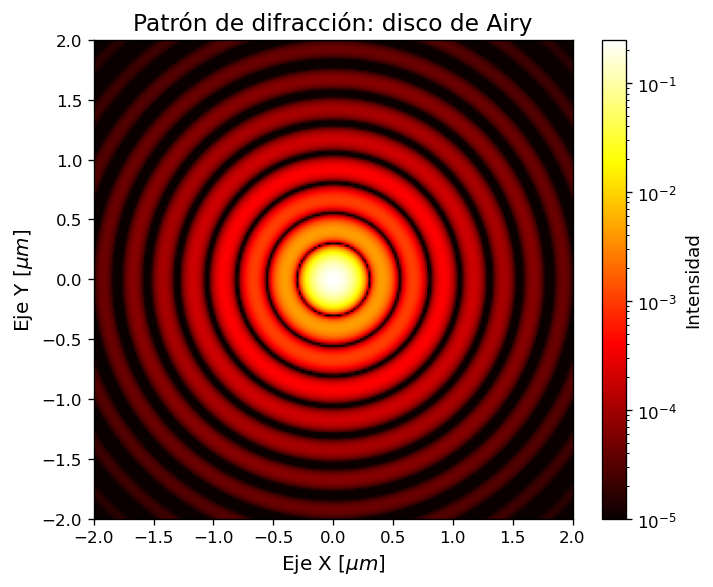

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import scipy as sp

def J(m, x):
    theta = np.linspace(0, np.pi, 1000)
    y = np.cos(m * theta - x * np.sin(theta))
    return (1 / np.pi) * sp.integrate.simpson(y, theta)
    
intervalo = np.linspace(-2e-6,2e-6,220)
X,Y= np.meshgrid(intervalo,intervalo)
r = np.sqrt(X**2 + Y**2)

λ = 500e-9
k = 2*np.pi/λ
I = np.zeros_like(r)

J_vect = np.vectorize(J)

mask = r > 0
I[~mask] = 0.25
I[mask] = (J_vect(1, k * r[mask]) / (k * r[mask]))**2

plt.style.use("default")
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)
img = ax.imshow(I, extent=[-2, 2, -2, 2], origin="lower", cmap="hot", norm=LogNorm(vmin=1e-5, vmax=I.max()))

cbar = fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Intensidad", fontsize=11)
ax.set_title("Patrón de difracción: disco de Airy", fontsize=14)
ax.set_xlabel("Eje X [$\mu m$]", fontsize=12)
ax.set_ylabel("Eje Y [$\mu m$]", fontsize=12)

plt.tight_layout()
plt.show()

### 3. Capacidad calorífica de un sólido

La teoría de sólidos de Debye dice que la capacidad calorífica de un sólido a una temperatura $T$ está dada por:

$$C_V = 9V \rho k_B \left(\frac{T}{\theta_D}\right)^3 \int_0^{\theta_D/T} \frac{x^4 e^x}{(e^x - 1)^2} dx $$

donde $V$ es el volumen del sólido, $
ho$ es la densidad numérica de los átomos, $k_B$ es la constante de Boltzmann y $\theta_D$ es la llamada temperatura de Debye, una propiedad de sólidos que depende de su densidad y la velocidad del sonido.

**(a)** Escribe una función $C_V(T)$ que calcule la $C_V$ para un valor dado de temperatura, de una muestra que consta de 1000 centímetros cúbicos de aluminio sólido, con densidad numérica de $\rho = 6.022 	\times 10^{28}\text{ m}^{-3}$ y una temperatura de Debye de $\theta_D = 428	\text{ K}$. Utiliza la cuadratura gaussiana para evaluar la integral, con $N=50$ puntos muestra.

**(b)** Usa tu función para hacer una gráfica de la capacidad calorífica en función de la temperatura desde $T=5 \text{ K}$ hasta $T=500 \text{ K}$.

### 4. Incertidumbre cuántica en el oscilador armónico

En unidades donde todas las constantes son 1, la función de onda del n-ésimo nivel de energía del oscilador armónico cuántico unidimensional, (i.e., una partícula puntual sin espín en un pozo de potencial cuadrático) está dada por:

$$ \psi_n(x) = \frac{1}{\sqrt{2^n n! \sqrt{\pi}}} e^{-x^2/2} H_n(x) $$

para $n=0...\infty$, donde $H_n(x)$ es el n-ésimo polinomio de Hermite. Los polinomios de Hermite satisfacen una relación algo similar a la de los números de Fibonacci, aunque más compleja:

$$ H_{n+1}(x) = 2x H_n(x) - 2n H_{n-1}(x) $$

Los dos primeros polinomios de Hermite son $H_0(x)=1$ y $H_1(x)=2x$.

**(a)** Escribe una función $H(n,x)$ que calcule $H_n(x)$ dados $x$ y cualquier número entero $n \ge 0$. Utiliza tu función para hacer una gráfica que muestre las funciones de onda del oscilador armónico para $n=0, 1, 2$ y $3$, todos en el mismo gráfico, en el rango de $x=-4$ a $x=4$. *Hint:* Hay una función factorial en el paquete `math` que calcula el factorial de un número entero.

In [34]:
def Hermite(n,x):
    if n < 0:
        raise ValueError("Esta función de Hermite solo está definida para n enteros no negativos.")
    elif isinstance(n,float):
        raise TypeError("Esta función solo está definida para n enteros no negativos.")
    elif n == 0:
        return 1
    elif n == 1:
        return 2*x
    else:
        return 2*x*Hermite(n-1,x)-2*(n-1)*Hermite(n-2,x)

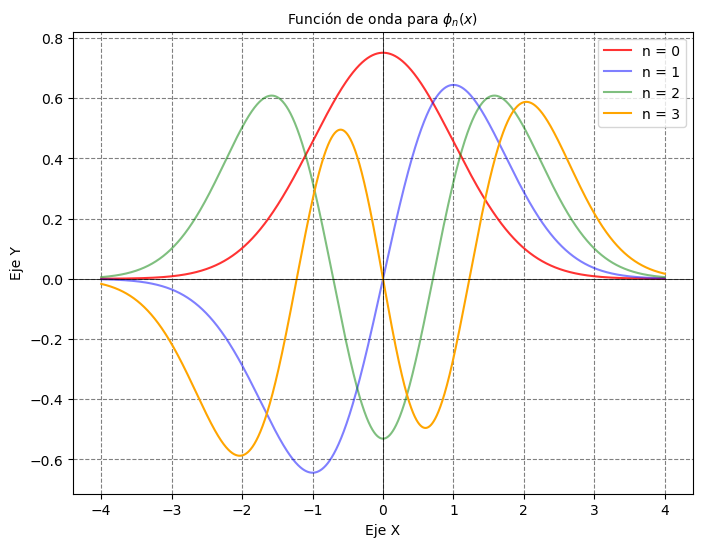

In [75]:
import numpy as np
import math as mt
import matplotlib.pyplot as plt

def phi_n(n,x):
    return (1/np.sqrt((2**n)*mt.factorial(n)*np.sqrt(np.pi)))*np.exp((-x**2)/2)*Hermite(n,x)

ejex = np.linspace(-4,4,100000)
ejey = [[],[],[],[]]
for m in range(0,4):
    for i in range(len(ejex)):
        valor_funcion_onda = phi_n(m,ejex[i])
        ejey[m].append(valor_funcion_onda)

plt.figure(figsize = (8,6))
plt.plot(ejex,ejey[0], color ="red", alpha = 0.8, label = "n = 0")
plt.plot(ejex,ejey[1], color ="blue", alpha = 0.5, label = "n = 1")
plt.plot(ejex,ejey[2], color ="green", alpha = 0.5, label = "n = 2")
plt.plot(ejex,ejey[3], color ="orange", alpha = 1, label = "n = 3")
plt.title("Función de onda para $\phi_n(x)$", fontsize = 10)
plt.legend()
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.axhline(y = 0, xmin = 0, color = 'black', linewidth = 0.5)
plt.axvline(x = 0, ymin = 0.0, color = 'black', linewidth = 0.5)
plt.grid(linestyle = "--", color ="gray")

**(b)** Haz una gráfica aparte, de la función de onda para $n=30$ desde $x=-10$ hasta $x=10$. *Hint:* si tu programa tarda demasiado en ejecutarse en este caso, entonces está haciendo mal el cálculo; el programa debería tardar aproximadamente un segundo en ejecutarse.

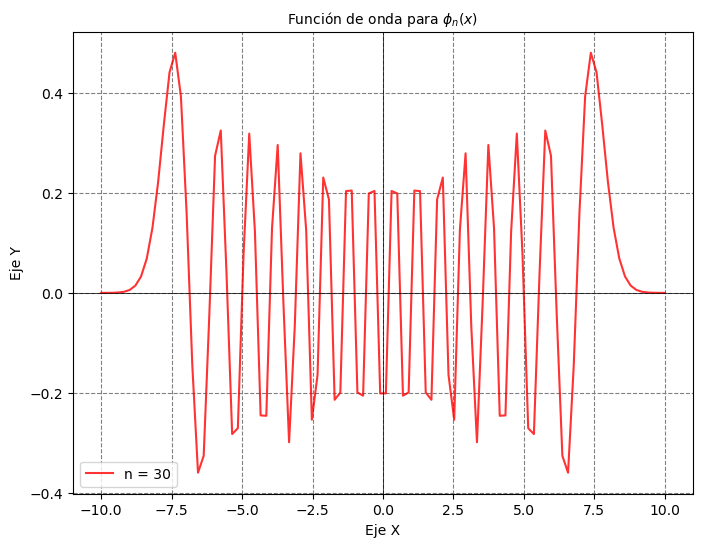

In [108]:
import numpy as np
import math as mt
import matplotlib.pyplot as plt

def phi_n(n,x):
    return (1/np.sqrt((2**n)*mt.factorial(n)*np.sqrt(np.pi)))*np.exp((-x*x)/2)*Hermite(n,x)

ejex2 = np.linspace(-10,10,100)
ejey2 = []
for i in range(len(ejex2)):
        valor_funcion_onda2 = phi_n(30,ejex2[i]) ##
        ejey2.append(valor_funcion_onda2)

plt.figure(figsize = (8,6))
plt.plot(ejex2,ejey2, color ="red", alpha = 0.8, label = "n = 30")
plt.title("Función de onda para $\phi_n(x)$", fontsize = 10)
plt.legend()
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.axhline(y = 0, xmin = 0, color = 'black', linewidth = 0.5)
plt.axvline(x = 0, ymin = 0.0, color = 'black', linewidth = 0.5)
plt.grid(linestyle = "--", color ="gray")

**(c)** La incertidumbre cuántica de una partícula en el n-ésimo nivel de un oscilador armónico cuántico se puede cuantificar mediante su media cuadrática $\sqrt{\langle x^2 \rangle}$, donde:

$$ \langle x^2 \rangle = \int_{-\infty}^{\infty} x^2 |\psi_n(x)|^2 dx $$

Escribe un programa que evalúe esta integral usando la cuadratura gaussiana en 100 puntos y luego calcula la incertidumbre (es decir, la posición media cuadrática de la partícula) para un valor dado de $n$. Utiliza tu programa para calcular la incertidumbre para $n=5$. Deberías obtener una respuesta cercana a $\sqrt{\langle x^2 \rangle} = 2.3$.

### 5. Atracción gravitacional de una lámina uniforme

Una lámina de metal cuadrada uniforme flota inmóvil en el espacio:


La lámina mide 10 m de lado, tiene un espesor insignificante y una masa de 10 toneladas.

**(a)** Considera la fuerza gravitacional debida a la placa que siente una masa puntual de 1 kg a una distancia $z$ del centro del cuadrado, en dirección perpendicular a la lámina, como se muestra en la figura. Demuestra que la componente de la fuerza a lo largo del eje z es:

$$ F_z = G\sigma z \iint_{-L/2}^{L/2} \frac{dx dy}{(x^2 + y^2 + z^2)^{3/2}} $$

donde $G = 6.674 	imes 10^{-11}	ext{ m}^3	ext{ kg}^{-1}	ext{ s}^{-2}$ es la constante gravitacional de Newton y $\sigma$ es la masa por unidad de área de la hoja.

**(b)** Escribe un programa para calcular y graficar la fuerza en función de $z$ de $z=0$ hasta $z=10	ext{ m}$. Para la integral doble utiliza la cuadratura Gaussiana (doble):

$$ I \simeq \sum_{i=1}^N \sum_{j=1}^N \omega_i \omega_j f(x_i, x_j) $$

con 100 puntos de muestra a lo largo de cada eje.

**(c)** Deberías ver una curva suave, excepto en valores muy pequeños de $z$, donde la fuerza debería caer repentinamente a cero. Esta caída no es un efecto real, sino un artefacto de la forma en que hemos realizado el cálculo. Explica brevemente de dónde viene este artefacto y sugiere una estrategia para eliminarlo, o al menos disminuir su tamaño.

*Este cálculo puede considerarse como un modelo de la atracción gravitacional de una galaxia. La mayor parte de la masa de una galaxia espiral (como nuestra Vía Láctea) se encuentra en un plano o disco delgado que pasa por el centro galáctico, y la atracción gravitacional ejercida por ese plano sobre cuerpos fuera de la galaxia se puede calcular con los métodos que hemos empleado aquí.*